In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import Callback, ModelCheckpoint
import time
import tensorflow as tf
from tensorflow import keras

# Data Generation

In [ ]:
# orginal function
def func1(x,d,e):
    y = d*(np.cos(x+e)+np.sin(x+e))
    return y

# estimator
def func2(x,a,b,c):
    y = a*np.cos(b*x+c)
    return y

(2000, 100) (2000, 2)
(200, 100) (200, 2)
(5000, 100) (5000, 3)


Text(0, 0.5, '$Y$ or $\\hat{Y}$')

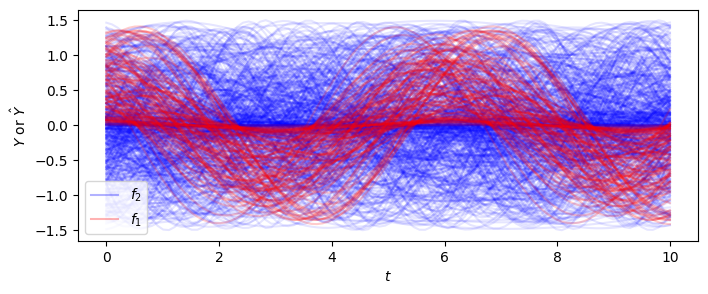

In [ ]:
# target data
org_data = []
org_features = []
np.random.seed(66)
x = np.linspace(0,10,100)
for i in range(2000):
  d = np.random.uniform(0,1)
  e = np.random.uniform(0,2)
  org = func1(x,d,e)
  org_data.append(org)
  org_features.append([d,e])

org_data = np.array(org_data)
org_features = np.array(org_features)
print(org_data.shape, org_features.shape)

# testing data
org_data_test = []
org_features_test = []
x = np.linspace(0,10,100)
for i in range(200):
  d = np.random.uniform(0,1)
  e = np.random.uniform(0,2)
  org = func1(x,d,e)
  org_data_test.append(org)
  org_features_test.append([d,e])
org_data_test = np.array(org_data_test)
org_features_test = np.array(org_features_test)
print(org_data_test.shape, org_features_test.shape)

# simulation data
sim_data = []
sim_features = []
for i in range(5000):
  a = np.random.uniform(0,1.5)
  b = np.random.uniform(0,2)
  c = np.random.uniform(-np.pi,np.pi)
  sim = func2(x,a,b,c)
  sim_data.append(sim)
  sim_features.append([a,b,c])

sim_data = np.array(sim_data)
sim_features = np.array(sim_features)
print(sim_data.shape, sim_features.shape)


# Plot simulated data with one label
plt.figure(figsize=(8, 3))
t = np.linspace(0,10,100)
for i in range(500):
    if i == 0:
        plt.plot(t, sim_data[i], color='b', alpha=0.3, label='$f_2$')
    else:
        plt.plot(t, sim_data[i], color='b', alpha=0.1)

# Plot original data with one label
for i in range(100):
    if i == 0:
        plt.plot(t, org_data[i], color='r', alpha=0.3, label='$f_1$')
    else:
        plt.plot(t, org_data[i], color='r', alpha=0.2)

plt.legend()
plt.xlabel('$t$')
plt.ylabel(r'$Y$ or $\hat{Y}$')  # Use raw string + LaTeX


# AssimNet

## Load Proxy

In [ ]:
proxy = tf.keras.models.load_model('your path')

## Load VAE

In [ ]:
class Sampling(keras.layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


In [ ]:
custom_objects = {'Sampling': Sampling}
vae_encoder_model = tf.keras.models.load_model('your path',custom_objects=custom_objects)
vae_decoder_model = tf.keras.models.load_model('your path')

## Define dependencies in AssimNet

In [ ]:
def kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p):
    """KL divergence between two multivariate diagonal Gaussians"""
    var_q = tf.exp(logvar_q)
    var_p = tf.exp(logvar_p)

    kl = 0.5 * (
        tf.reduce_sum(logvar_p - logvar_q, axis=1)  # log |Σ_p| / |Σ_q|
        - tf.cast(tf.shape(mu_q)[1], tf.float32)    # -k
        + tf.reduce_sum(var_q / var_p, axis=1)       # Tr(Σ_p^-1 Σ_q)
        + tf.reduce_sum((mu_p - mu_q)**2 / var_p, axis=1)  # diff^T Σ_p^-1 diff
    )
    return tf.reduce_mean(kl)

class Build_AssimNet(keras.Model):
    def __init__(self, assim_encoder, vae_encoder, decoder, proxy, **kwargs):
        super().__init__(**kwargs)
        self.assim_encoder = assim_encoder
        self.vae_encoder = vae_encoder
        self.decoder = decoder
        self.proxy = proxy
        self.lam = 0.001
        self.assim_loss_tracker = keras.metrics.Mean(name="assim_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")
        self.recons_loss_tracker = keras.metrics.Mean(name="recons_loss")
        self.val_loss_tracker = keras.metrics.Mean(name="vaL_loss")
        self.optimizer = tf.keras.optimizers.Adam(learning_rate = 0.0001)

        # Set decoder and proxy as untrainable
        self.vae_encoder.trainable = False
        self.decoder.trainable = False
        self.proxy.trainable = False

    @property
    def metrics(self):
        return [self.assim_loss_tracker,
                self.kl_loss_tracker,
                self.recons_loss_tracker,
                self.val_loss_tracker]

    def train_step(self, data):
        en_features = data[0][0]
        assim_target = data[0][1]

        with tf.GradientTape() as tape:
            mu_q, logvar_q, z = self.assim_encoder(en_features)
            # Disgnostic
            recons4vae_encoder = self.decoder(z)
            mu_p, logvar_p, _ = self.vae_encoder(recons4vae_encoder)
            kl_loss = kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p)

            simu_in_recons = self.decoder(z)
            proxy_out = self.proxy(simu_in_recons)
            recons_loss = tf.keras.losses.MeanSquaredError()(proxy_out, assim_target)
            assim_loss = recons_loss + self.lam*kl_loss

        grads = tape.gradient(assim_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.assim_loss_tracker.update_state(assim_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        self.recons_loss_tracker.update_state(recons_loss)

        return {"assim_loss": self.assim_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result(),
                "recons": self.recons_loss_tracker.result()}

    def test_step(self, data):
        en_features = data[0][0]
        assim_target = data[0][1]

        _, _, z = self.assim_encoder(en_features)

        simu_in_recons = self.decoder(z)
        proxy_out = self.proxy(simu_in_recons)
        recons_loss = tf.keras.losses.MeanSquaredError()(proxy_out, assim_target)

        self.val_loss_tracker.update_state(recons_loss)

        return {
            "val_loss": self.val_loss_tracker.result(),
        }


    def predict(self, x_input, verbose = 0):
      """
      Forward pass through the AssimNet pipeline: encoder → decoder → proxy
      """
      z_mean, z_log_var, z = self.assim_encoder.predict(x_input, verbose=verbose)
      simu_in_pred = self.decoder.predict(z, verbose=verbose)
      y_pred = self.proxy.predict(simu_in_pred, verbose=verbose)
      return y_pred

    def predict_hard(self, x_input, x_eval_range, verbose = 0):
      """
      Forward pass through the AssimNet pipeline: encoder → decoder → function
      """
      z_mean, z_log_var, z = self.assim_encoder.predict(x_input, verbose=verbose)
      simu_in_pred = self.decoder.predict(z, verbose=verbose)  # shape: (batch_size, 3)

      a_vals = simu_in_pred[:, 0]
      b_vals = simu_in_pred[:, 1]
      c_vals = simu_in_pred[:, 2]

      # Evaluate func2 for each sample in the batch
      y_pred = np.array([
          func2(x_eval_range, a, b, c)
          for a, b, c in zip(a_vals, b_vals, c_vals)
      ])

      y_pred = y_pred[..., np.newaxis]

      return y_pred  # shape: (batch_size, len(x_eval_range))

# Define Models

In [ ]:
def attention_block(inputs):
    attention = keras.layers.Dense(1, activation='tanh')(inputs)
    attention = keras.layers.Flatten()(attention)
    attention = keras.layers.Activation('softmax')(attention)
    attention = keras.layers.RepeatVector(128)(attention)
    attention = keras.layers.Permute([2, 1])(attention)
    return keras.layers.Multiply()([inputs, attention])

In [ ]:
def train_assim(x_train, y_train, epochs=100, batch_size=512, val_split=0.05, callbacks=None, verbose=0):
    # Rebuild encoder
    encoder_input = keras.layers.Input(shape=(2,))
    x = keras.layers.Dense(128, activation='relu')(encoder_input)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Dense(128, activation='relu')(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Flatten()(x)
    z_mean = keras.layers.Dense(32, name="z_mean")(x)
    z_log_var = keras.layers.Dense(32, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])
    assim_encoder = keras.Model(inputs=encoder_input, outputs=[z_mean, z_log_var, z], name="Assim_encoder")

    # Create a new AssimNet model instance
    assimnet_model = Build_AssimNet(assim_encoder, vae_encoder_model, vae_decoder_model, proxy)
    assimnet_model.compile(tf.keras.optimizers.Adam())

    # Fit the model
    assimnet_model.fit([x_train, y_train],
                       epochs=epochs,
                       batch_size=batch_size,
                       validation_split =val_split,
                       callbacks=callbacks,
                       verbose=verbose)

    return assimnet_model

def train_gruatt(x_train, y_train, epochs=500, batch_size=512, val_split=0.05, callbacks=None, verbose=0):
    inputs = keras.layers.Input(shape=(x_train.shape[1],))
    x = keras.layers.RepeatVector(y_train.shape[1])(inputs)  # repeat for time steps
    x = keras.layers.GRU(128, return_sequences=True)(x)
    x = keras.layers.Dropout(0.2)(x)
    x = attention_block(x)
    x = keras.layers.GRU(128, return_sequences=True)(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Dense(128, activation='relu')(x)
    output = keras.layers.Dense(1, activation='linear')(x)

    model = keras.models.Model(inputs=inputs, outputs=output)
    model.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=0.0001))

    model.fit(x_train, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=val_split,
              callbacks=callbacks,
              verbose=verbose)

    return model

def train_gru(x_train, y_train, epochs=500, batch_size=512, val_split=0.05, callbacks=None, verbose=0):
    """
    Train a simple GRU-based sequence prediction model.
    """
    inputs = keras.layers.Input(shape=(x_train.shape[1],))  # e.g., shape (2,)
    x = keras.layers.RepeatVector(y_train.shape[1])(inputs)  # repeat for time steps (e.g., 100)
    x = keras.layers.GRU(128, return_sequences=True)(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.GRU(128, return_sequences=True)(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Dense(128, activation='relu')(x)
    output = keras.layers.Dense(1, activation='linear')(x)

    model = keras.models.Model(inputs=inputs, outputs=output)
    model.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=0.0001))

    model.fit(x_train, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=val_split,
              callbacks=callbacks,
              verbose=verbose)

    return model

def train_lstm(x_train, y_train, epochs=500, batch_size=512, val_split=0.05, callbacks=None, verbose=0):
    """
    Train a simple LSTM-based sequence prediction model.
    """
    inputs = keras.layers.Input(shape=(x_train.shape[1],))  # e.g., shape (2,)
    x = keras.layers.RepeatVector(y_train.shape[1])(inputs)  # repeat for time steps (e.g., 100)
    x = keras.layers.LSTM(128, return_sequences=True)(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.LSTM(128, return_sequences=True)(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Dense(128, activation='relu')(x)
    output = keras.layers.Dense(1, activation='linear')(x)

    model = keras.models.Model(inputs=inputs, outputs=output)
    model.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=0.0001))

    model.fit(x_train, y_train,
              epochs=epochs,
              batch_size=batch_size,
              validation_split=val_split,
              callbacks=callbacks,
              verbose=verbose)

    return model

In [ ]:
from tensorflow.keras.models import load_model
def load_assimnet_with_saved_encoder(assim_path, vae_encoder, decoder, proxy):
    """
    Loads AssimNet with a saved encoder and return reconstructed Build_AssimNet model
    """
    # Load the saved encoder
    custom_objects = {'Sampling': Sampling}
    assim_encoder = load_model(assim_path, custom_objects=custom_objects)

    # Rebuild AssimNet
    assimnet = Build_AssimNet(
        assim_encoder=assim_encoder,
        vae_encoder=vae_encoder,
        decoder=decoder,
        proxy=proxy
    )

    # Compile to ensure optimizer and losses are ready
    assimnet.compile(tf.keras.optimizers.Adam())

    return assimnet

# Run Models

In [ ]:
from sklearn.metrics import mean_squared_error
import os

# Automatically save the model with the lowest val_loss
class SaveBestModelCallback(Callback):
    def __init__(self, model_path, monitor='val_loss', save_best_only=True):
        super().__init__()
        self.model_path = model_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: metric '{self.monitor}' not found in logs.")
            return

        if not self.save_best_only or current < self.best:
            self.best = current
            self.model.save(self.model_path)
            # print(f"✅ Saved best model at epoch {epoch+1} with {self.monitor}: {current:.6f}")

# Save the AssimNet encoder
class SaveEncoderDecoder(Callback):
    def __init__(self, encoder_path, monitor='assim_loss', save_best_only=True):
        super().__init__()
        self.encoder_path = encoder_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')  # initialize as very bad (infinite loss)

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: Metric '{self.monitor}' not found in logs.")
            return

        # Save if either not save_best_only or new best
        if not self.save_best_only or current < self.best:
            self.best = current
            # print(f"✅ Saved best model at epoch {epoch+1} with {self.monitor}: {current:.6f}")
            self.model.assim_encoder.save(self.encoder_path)

def evaluate_model(model, x_test, y_test, mode="soft", x_eval_range=None, if_assim = True):
    rmses = []
    if if_assim:
      n_run = 30
    else:
      n_run = 1
    for _ in range(n_run):
      if mode == "hard":
          assert x_eval_range is not None, "x_eval_range is required for hard mode"
          preds = model.predict_hard(x_test, x_eval_range, verbose=0)
      else:
          preds = model.predict(x_test, verbose=0)

      rmse = np.sqrt(mean_squared_error(y_test.reshape(-1), preds.reshape(-1)))
      rmses.append(rmse)

    return np.mean(rmses)

In [ ]:
def run_comparison(x_data, y_data, train_split, save_dir):
    assert 0 < train_split <= 1.0, "train_split must be in (0, 1]"

    num_train = int(len(x_data) * train_split)
    indices = np.random.permutation(len(x_data))[:num_train]
    x_train, y_train = x_data[indices], y_data[indices]

    batch_size = max(1, int(num_train * 0.3))
    print(f"\n📦 Training with {num_train} samples (batch size: {batch_size})")

    # File paths
    assim_path = os.path.join(save_dir, f"assimnet_encoder_{num_train}.keras")
    gru_path = os.path.join(save_dir, f"gru_{num_train}.keras")
    gruatt_path = os.path.join(save_dir, f"gruatt_{num_train}.keras")
    lstm_path = os.path.join(save_dir, f"lstm_{num_train}.keras")

    # === Train and Save Models ===
    print("🏋️‍♂️ Training AssimNet...")
    assimnet = train_assim(x_train, y_train, epochs=3000, batch_size=batch_size,
                           callbacks=[SaveEncoderDecoder(assim_path, monitor='val_val_loss')])

    print("🏋️‍♂️ Training GRU...")
    gru = train_gru(x_train, y_train, epochs=1000, batch_size=batch_size,
                    callbacks=[SaveBestModelCallback(gru_path, monitor='val_loss')])

    print("🏋️‍♂️ Training GRU-ATT...")
    gruatt = train_gruatt(x_train, y_train, epochs=1000, batch_size=batch_size,
                          callbacks=[SaveBestModelCallback(gruatt_path, monitor='val_loss')])

    print("🏋️‍♂️ Training LSTM...")
    lstm = train_lstm(x_train, y_train, epochs=1000, batch_size=batch_size,
                      callbacks=[SaveBestModelCallback(lstm_path, monitor='val_loss')])

    return num_train

def calculate_comparison_score(x_test, y_test, num_train, save_dir,
                                vae_encoder_model=None, vae_decoder_model=None, proxy=None):
    """
    Loads the best saved models and evaluates them on the test set.
    """
    assert x_test.shape[0] == y_test.shape[0], "Mismatch in test input/output sizes"

    # File paths
    assim_path = os.path.join(save_dir, f"assimnet_encoder_{num_train}.keras")
    gru_path = os.path.join(save_dir, f"gru_{num_train}.keras")
    gruatt_path = os.path.join(save_dir, f"gruatt_{num_train}.keras")
    lstm_path = os.path.join(save_dir, f"lstm_{num_train}.keras")

    print(f"\n📤 Loading best models for {num_train} samples...")

    # Load models
    gru = load_model(gru_path)
    gruatt = load_model(gruatt_path)
    lstm = load_model(lstm_path)

    assimnet = load_assimnet_with_saved_encoder(
        assim_path=assim_path,
        vae_encoder=vae_encoder_model,
        decoder=vae_decoder_model,
        proxy=proxy
    )

    x_eval_range = np.linspace(0, 10, y_test.shape[1])

    print("🔍 Evaluating models...")
    results = {
        "assimnet_soft": evaluate_model(assimnet, x_test, y_test, mode="soft",if_assim = True),
        "assimnet_hard": evaluate_model(assimnet, x_test, y_test, mode="hard", x_eval_range=x_eval_range,if_assim = True),
        "gru": evaluate_model(gru, x_test, y_test,if_assim = False),
        "gruatt": evaluate_model(gruatt, x_test, y_test,if_assim = False),
        "lstm": evaluate_model(lstm, x_test, y_test,if_assim = False),
    }

    return results

In [ ]:
import json
# === Run Comparison ===
all_scores = {}
splits = [1, 0.5, 0.25, 0.1, 0.05, 0.025]
n = 0
for split in splits:
    print(f"Case number: {n+1}, split: {split}")
    num_train = int(len(org_features) * split)
    scores = calculate_comparison_score(org_features_test, org_data_test, num_train, save_dir=save_dir,
                                        vae_encoder_model=vae_encoder_model,
                                        vae_decoder_model=vae_decoder_model,
                                        proxy=proxy)
    print(f"Split: {split}, Scores: {scores}")
    # ✅ Convert all NumPy float values to native Python floats
    clean_scores = {k: float(v) for k, v in scores.items()}
    all_scores[int(len(org_features) * split)] = clean_scores
    n += 1

# ✅ Save as JSON
with open("assimnet_rmse_results.json", "w") as f:
    json.dump(all_scores, f, indent=4)

print("✅ Saved as 'assimnet_rmse_results.json'")

Case number: 1, split: 1

📤 Loading best models for 2000 samples...
🔍 Evaluating models...


Split: 1, Scores: {'assimnet_soft': np.float64(0.02452859497430373), 'assimnet_hard': np.float64(0.024054920414938025), 'gru': np.float64(0.035169344351985245), 'gruatt': np.float64(0.026565897703112632), 'lstm': np.float64(0.028492945558656568)}
Case number: 2, split: 0.5

📤 Loading best models for 1000 samples...
🔍 Evaluating models...
Split: 0.5, Scores: {'assimnet_soft': np.float64(0.02584722660880634), 'assimnet_hard': np.float64(0.025567257469798852), 'gru': np.float64(0.02988048536963021), 'gruatt': np.float64(0.026243207674957164), 'lstm': np.float64(0.03484933420828967)}
Case number: 3, split: 0.25

📤 Loading best models for 500 samples...
🔍 Evaluating models...
Split: 0.25, Scores: {'assimnet_soft': np.float64(0.025579457592951896), 'assimnet_hard': np.float64(0.025266141365166393), 'gru': np.float64(0.028780860922855374), 'gruatt': np.float64(0.028233498414566474), 'lstm': np.float64(0.03884023212335131)}
Case number: 4, split: 0.1

📤 Loading best models for 200 samples...
🔍

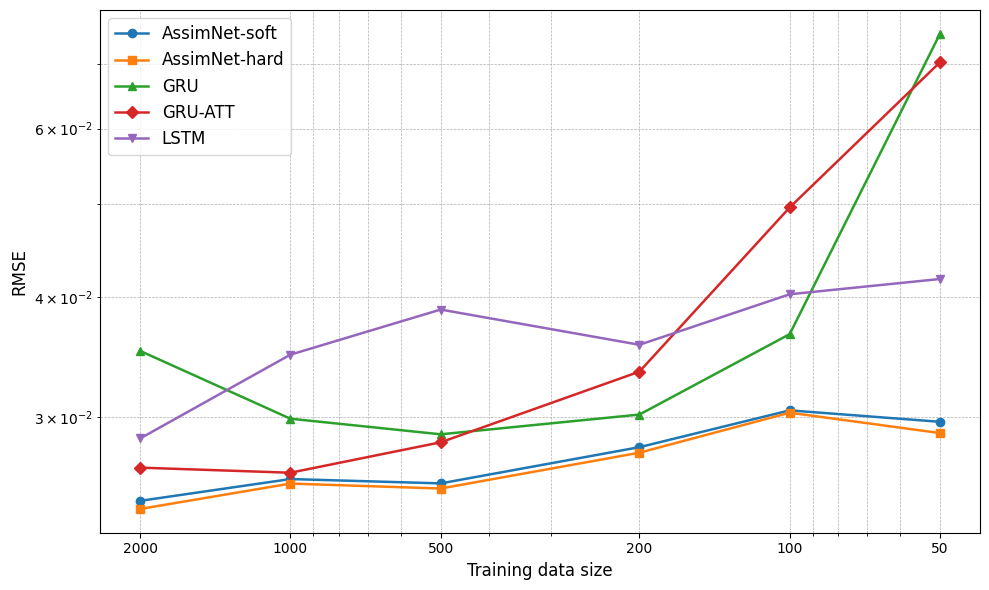

In [ ]:
def plot_all_scores(all_scores):
    # Sort keys from high to low (for left-to-right decreasing x-axis)
    sorted_sizes = sorted(all_scores.keys(), reverse=True)

    # Get model names
    model_names = list(all_scores[sorted_sizes[0]].keys())
    plt.figure(figsize=(10, 6))
    label_names = ['AssimNet-soft', 'AssimNet-hard', 'GRU', 'GRU-ATT', 'LSTM']
    markers = ['o', 's', '^', 'D', 'v']
    # Plot RMSE for each model
    for i, model in enumerate(model_names):
        rmse_values = [all_scores[size][model] for size in sorted_sizes]
        plt.plot(sorted_sizes, rmse_values, marker=markers[i], label=label_names[i], linewidth=1.8)

    # Force log-scale ticks to include these values
    custom_ticks = [2000, 1000, 500, 200, 100, 50]
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(custom_ticks, labels=[str(t) for t in custom_ticks])

    # Enable major and minor grid lines
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.minorticks_on()

    # Labels and formatting
    # plt.title("RMSE vs Training Sample Size")
    plt.xlabel("Training data size", fontsize = 12)
    plt.ylabel("RMSE", fontsize = 12)
    plt.legend(fontsize = 12)
    plt.tight_layout()
    plt.gca().invert_xaxis()
    plt.show()
plot_all_scores(all_scores)